# 01 · MNIST 결과 보기

`exercise.py --run`이 저장한 `outputs/01_mnist/<실행이름>/`을 읽어 그림 3장을 그립니다. 학습 코드는 여기에 두지 않습니다.

먼저 `exercise.py`의 `save_results()`를 작성하고 `--run`을 실행하세요. matplotlib 기본 글꼴에는 한글이 없으므로 그림 안의 글자는 영어로 씁니다.

In [1]:
import json
import runpy

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
from torchvision import datasets

ns = runpy.run_path("../learning/01_mnist/exercise.py")  # exercise.py의 상수·함수를 불러옵니다
run_dir = ns["OUTPUT_DIR"] / ns["RUN_NAME"]  # 다른 실행은 ns["OUTPUT_DIR"] / "mlp_seed42"처럼 지정
run_dir

PosixPath('/home/minwoo/Develop/model-finetuning/outputs/01_mnist/cnn_seed42')

In [2]:
# TODO: run_dir / "metrics.json"은 metrics(dict)로, run_dir / "predictions.jsonl"은 한 줄씩 dict로 바꿔 predictions(list)로 읽으세요.

with open(run_dir / "metrics.json", 'r') as f:
    metrics = json.load(f)

with open(run_dir / "predictions.jsonl", 'r') as f:
    predictions = [json.loads(line) for line in f.readlines()]

## 1. 학습 곡선

loss가 내려가다 평평해지면 정상입니다. 끝까지 계속 내려가면 epoch을 늘려 볼 만합니다.

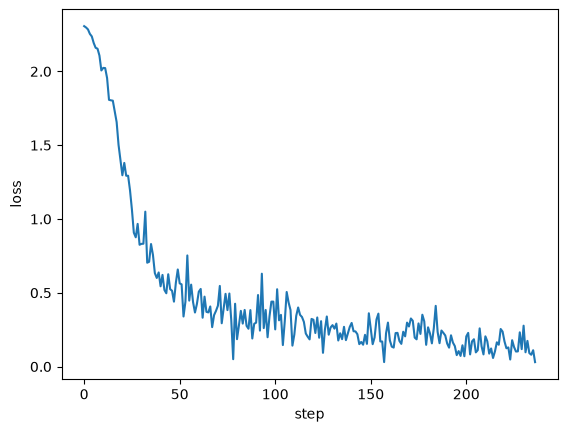

In [3]:
# TODO: metrics의 step별 train loss로 곡선을 그리고 run_dir / "train_loss.png"로 저장하세요.
# 힌트: fig, ax = plt.subplots() → ax.plot(...) → ax.set(xlabel=..., ylabel=...) → fig.savefig(...)

train_losses = metrics['train_losses']
X = range(len(train_losses))

fig, ax = plt.subplots() # 1개 plot을 그려도 사용할 수 있음 (그래프 요소들을 명확히 제어 가능)
ax.plot(X, train_losses)
ax.set(xlabel='step', ylabel='loss')
fig.show()
fig.savefig(run_dir / "train_loss.png") # 저장

## 2. 혼동행렬

대각선 밖에서 숫자가 큰 칸이 모델이 자주 헷갈리는 숫자 쌍입니다.

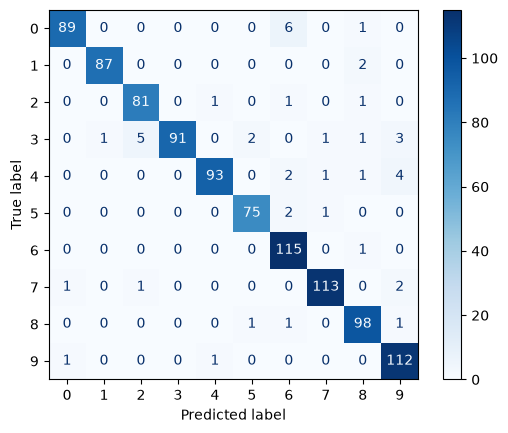

In [4]:
SPLIT = "validation"  # test는 설정을 다 고른 뒤 마지막에만 봅니다

# TODO: metrics[SPLIT]의 혼동행렬을 그리고 run_dir / f"confusion_{SPLIT}.png"로 저장하세요.
# 힌트: disp = ConfusionMatrixDisplay(np.array(...)).plot(cmap="Blues") → disp.figure_.savefig(...)

confusion_matrix = metrics[SPLIT]["confusion_matrix"]
disp = ConfusionMatrixDisplay(
    np.array(confusion_matrix)
).plot(cmap='Blues')
disp.figure_.savefig(run_dir / f"confusion_{SPLIT}.png")

## 3. 오답 20장

`results.md`의 실패 사례 칸에 옮길 근거입니다.

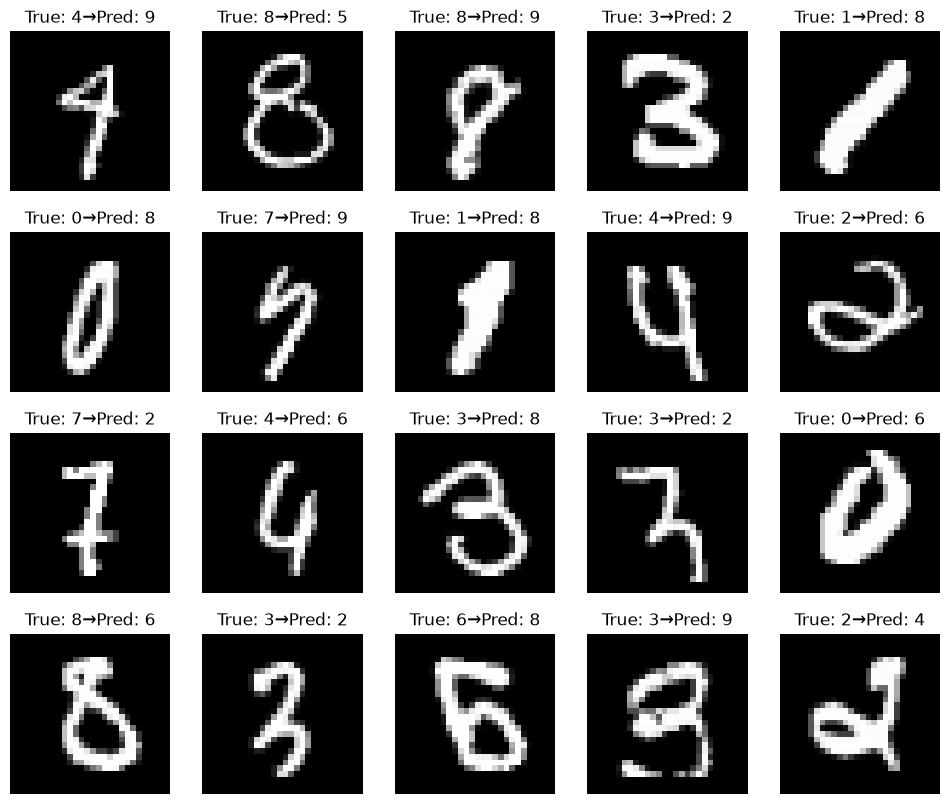

In [6]:
# validation 인덱스는 공식 train, test 인덱스는 공식 test 기준입니다.
mnist = datasets.MNIST(ns["DATA_DIR"], train=(SPLIT == "validation"))

# TODO: predictions에서 SPLIT의 오답만 골라 앞 20개를 4×5 격자로 그리고 run_dir / f"mistakes_{SPLIT}.png"로 저장하세요.
# 힌트: fig, axes = plt.subplots(4, 5) → image, _ = mnist[p["mnist_index"]] → ax.imshow(image, cmap="gray")
#       → ax.set_title(f"{p['label']}→{p['pred']}") → ax.axis("off")

wrong_answer = []
for prediction in predictions:
    if prediction['split'] != SPLIT:
        continue
    if prediction['label'] != prediction['pred']:
        wrong_answer.append(prediction)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, ax in enumerate(axes.flatten()):
    p = wrong_answer[i]
    image, _ = mnist[p["mnist_index"]]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: {p['label']}→Pred: {p['pred']}")
    ax.axis('off')

fig.savefig(run_dir / f"mistakes_{SPLIT}.png")